Model: "Vgg16 Functional model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_2 (InputLayer)            [(None, 128, 128, 3) 0                                            
__________________________________________________________________________________________________
conv2d_13 (Conv2D)              (None, 128, 128, 64) 1792        input_2[0][0]                    
__________________________________________________________________________________________________
conv2d_14 (Conv2D)              (None, 128, 128, 64) 36928       conv2d_13[0][0]                  
__________________________________________________________________________________________________
max_pooling2d_5 (MaxPooling2D)  (None, 64, 64, 64)   0           conv2d_14[0][0]                  
_____________________________________________________________________________

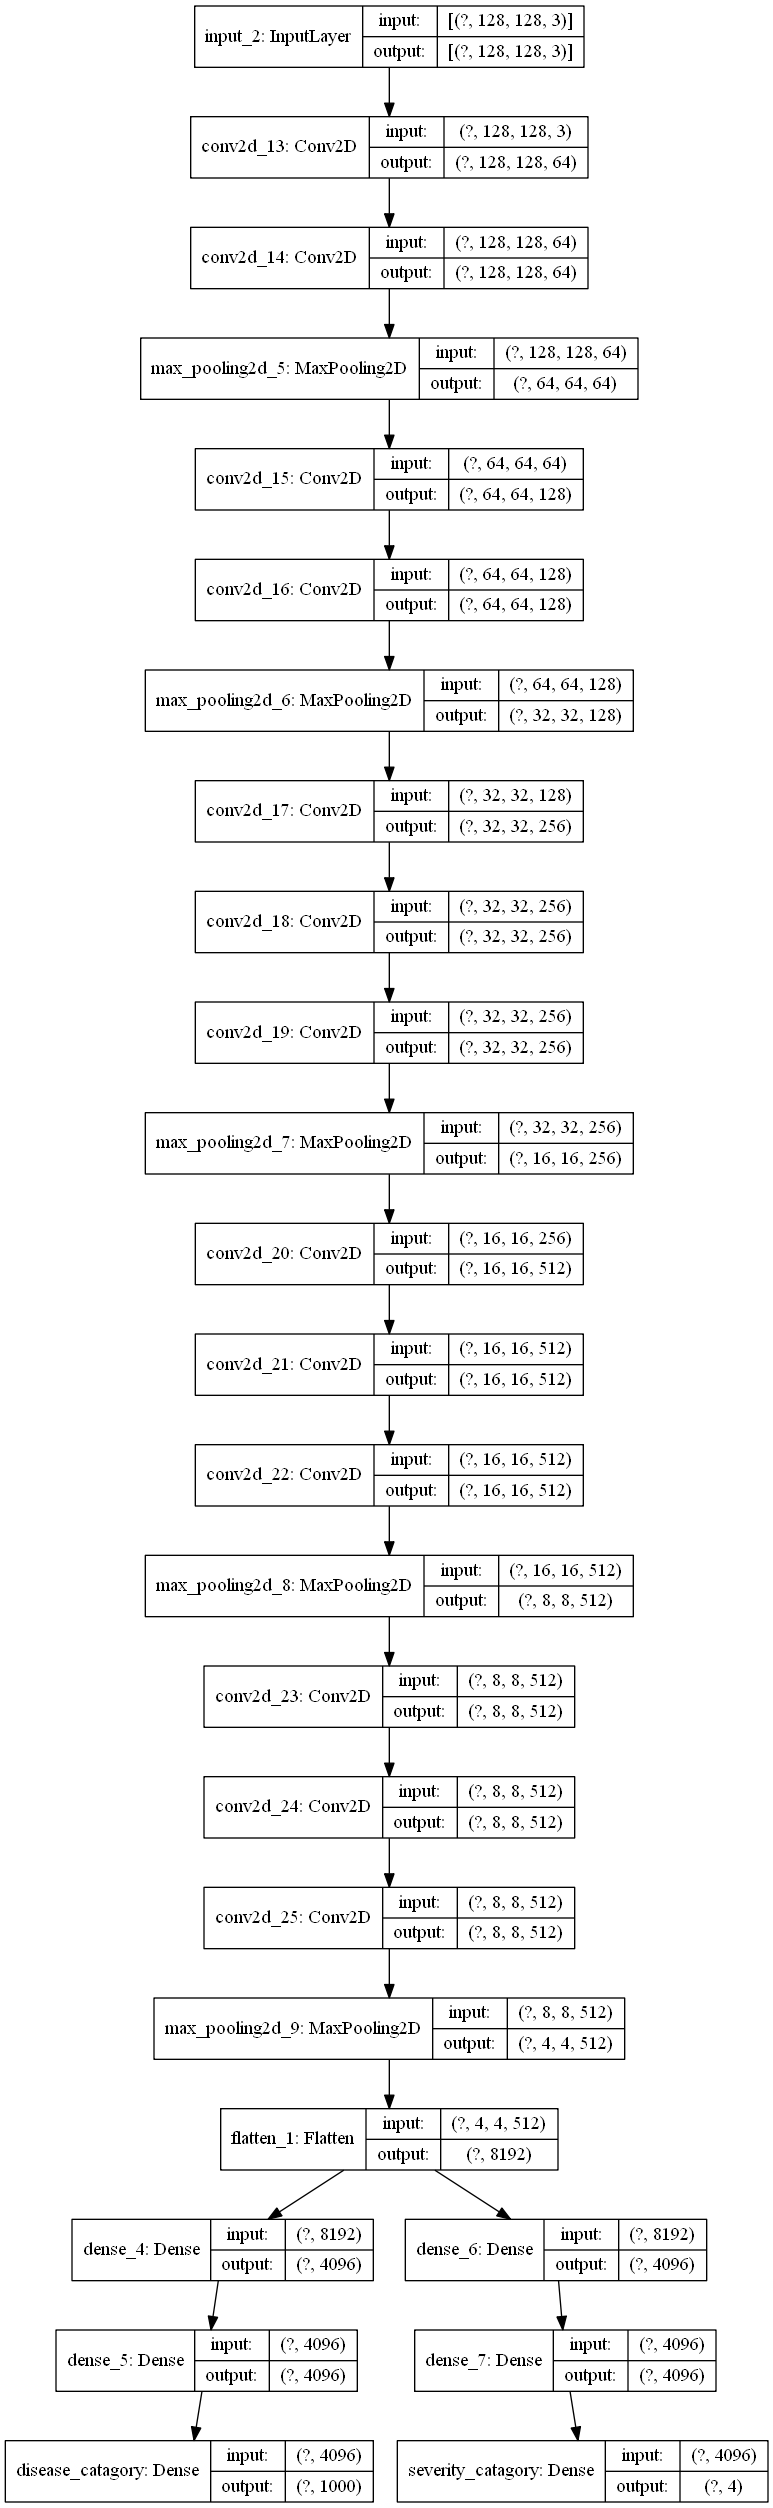

In [2]:
from keras.layers import Input, Conv2D, MaxPooling2D
from keras.layers import Dense, Flatten
from keras.models import Model
from tensorflow.keras.utils import plot_model

_input = Input((128,128,3)) 

conv1  = Conv2D(filters=64, kernel_size=(3,3), padding="same", activation="relu")(_input)
conv2  = Conv2D(filters=64, kernel_size=(3,3), padding="same", activation="relu")(conv1)
pool1  = MaxPooling2D((2, 2))(conv2)

conv3  = Conv2D(filters=128, kernel_size=(3,3), padding="same", activation="relu")(pool1)
conv4  = Conv2D(filters=128, kernel_size=(3,3), padding="same", activation="relu")(conv3)
pool2  = MaxPooling2D((2, 2))(conv4)

conv5  = Conv2D(filters=256, kernel_size=(3,3), padding="same", activation="relu")(pool2)
conv6  = Conv2D(filters=256, kernel_size=(3,3), padding="same", activation="relu")(conv5)
conv7  = Conv2D(filters=256, kernel_size=(3,3), padding="same", activation="relu")(conv6)
pool3  = MaxPooling2D((2, 2))(conv7)

conv8  = Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu")(pool3)
conv9  = Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu")(conv8)
conv10 = Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu")(conv9)
pool4  = MaxPooling2D((2, 2))(conv10)

conv11 = Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu")(pool4)
conv12 = Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu")(conv11)
conv13 = Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu")(conv12)
pool5  = MaxPooling2D((2, 2))(conv13)

flat   = Flatten()(pool5)
dense1 = Dense(4096, activation="relu")(flat)
dense2 = Dense(4096, activation="relu")(dense1)
#classes=7
output = Dense(1000, activation="softmax", name="disease_catagory")(dense2)
#edited 3 following lines 
dense1_2 = Dense(4096, activation="relu")(flat)
dense2_2 = Dense(4096, activation="relu")(dense1_2)
#classes=3
output_2 = Dense(4, activation="softmax",name="severity_catagory")(dense2_2)


model  = Model(inputs=_input, outputs=[output,output_2],name="Vgg16 Functional model")
model.summary()
plot_model(model, to_file='multilayer_perceptron_graph.png',show_shapes=True)

In [15]:
from tensorflow import keras
loss1=keras.losses.SparseCategoricalCrossentropy(from_logits=False)
loss2=keras.losses.SparseCategoricalCrossentropy(from_logits=False)
optim=keras.optimizers.Adam(lr=0.0001)
metrics=["accuracy"]
losses={"disease_catagory":loss1,
        "severity_catagory":loss2,
       }
model.compile(loss=losses,optimizer=optim,metrics=metrics)

In [14]:
#before defining the methods for shaffle Net V2 block import important libraries
from tensorflow.keras.layers import Input,Conv2D,DepthwiseConv2D,Dense,Concatenate, \
Add,ReLU,BatchNormalization,AvgPool2D,MaxPool2D,Reshape,Permute,Lambda


In [7]:
#number is  the batch size of inputs and x is input
"""
def channel_shuffle(inputs, num_groups=8):
    n, h, w, c = inputs.get_shape()
    x = tf.reshape(inputs, [-1, h, w, num_groups, c // num_groups])
    x_transponse = tf.transpose(x, [0, 1, 2, 4, 3])
    x_reshape = tf.reshape(x_transponse, [-1, h, w, c])
    return x_reshape

"""
def channel_shuffle(x,groups):
    number,width,height,channels=x.get_shape().as_list()
    group_channel=channel//groups
    x=Reshape([width,height,group_channel,groups])(x)
    #transpose x  where zero is batch size we can ignore it
    x=Permute([0,1,2,4,3])(x)
    x=Reshape(-1,width,height,channels)(x)
    return x
    


In [8]:
"""def channel_split(inputs, num_splits=2):
    c = inputs.get_shape()[3]
    input1, input2 = tf.split(inputs, [int(c // num_splits), int(c // num_splits)], axis=3)
    return input1, input2"""
def channel_split(x, num_splits=2):
    c = x.get_shape()[3]
    input1, input2 = tf.split(x, [int(c // num_splits), int(c // num_splits)], axis=3)
    return input1, input2

In [16]:
def shaflenet_block(inputs,strides=1,groups=3):
    input1,input2= channel_split(inputs, num_splits=2)
    input2=Conv2D(input2, kernel_size=(1,1),padding='same')#?
    
    input2=BatchNormalization(input2)
    input2=ReLU(input2)
    
    input2=DepthwiseConv2D(3,strides=strides,padding='same')(input2)
    
    input2=BatchNormalization(input2)
    
    input2=Conv2D(input2, kernel_size=(1,1),padding='same')#?
    
    input2=BatchNormalization(input2)
    input2=ReLU(input2)
    
    input2=Concatenate()([input1,input2])
    input2=channel_shuffle(input2,groups=3)
    return input2
    

In [17]:
def shaflenet_block_down_sample(inputs,strides,groups=3):
   # input1,input2= channel_split(inputs, num_splits=2)
    input2=1*1conv?(inputs,....)
    
    input2=BatchNormalization(input2)
    input2=ReLU(input2)
    input2=DepthwiseConv2D(3,strides=strides,padding='same')(input2)
    input2=BatchNormalization(input2)
    input2=1*1conv?
    input2=BatchNormalization(input2)
    input2=ReLU(input2)  
    
    input1=DepthwiseConv2D(3,strides=strides,padding='same')(inputs)
    input1=BatchNormalization(input1)
    input1=1*1conv?
    input1=BatchNormalization(input1)
    input1=ReLU(input1)
    
    input2=Concatenate()([input1,input2])
    input2=channel_shuffle(input2,groups=3)
    return input2
    
    input2=BatchNormalization(input2)
    input2=ReLU(input2)
    return input2

SyntaxError: invalid syntax (Temp/ipykernel_11920/1562090088.py, line 3)

In [18]:
# import the needed libraries
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Activation
from tensorflow.keras import backend as K
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# config
img_width, img_height = 28,28 #width & height of input image
input_depth = 1 #1: gray image
train_data_dir = 'DABC/OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/train' #data training path
testing_data_dir = 'DABC/OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/test' #data testing path
epochs = 2 #number of training epoch
batch_size = 5 #training batch size

# define image generator for Keras,
# here, we map pixel intensity to 0-1
train_datagen = ImageDataGenerator(rescale=1/255)
test_datagen = ImageDataGenerator(rescale=1/255)

# read image batch by batch
train_generator = train_datagen.flow_from_directory(
    train_data_dir,
    color_mode='rgb',#inpput iameg: gray
    target_size=(img_width,img_height),#input image size
    batch_size=batch_size,#batch size
    class_mode='categorical')#categorical: one-hot encoding format class label
testing_generator = test_datagen.flow_from_directory(
    testing_data_dir,
    color_mode='RGB',
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical')

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'DABC/OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/train'

In [19]:
model.fit_generator(
    train_generator,#our training generator
    #number of iteration per epoch = number of data / batch size
    steps_per_epoch=np.floor(train_generator.n/batch_size),
    epochs=epochs,#number of epoch
    validation_data=testing_generator,#our validation generator
    #number of iteration per epoch = number of data / batch size
    validation_steps=np.floor(testing_generator.n / batch_size))


NameError: name 'train_generator' is not defined

In [ ]:
print("Training is done!")
model.save('./model/modelLeNet5.h5')
print("Model is successfully stored!")


In [6]:
from tensorflow import keras

train_ds = keras.image_dataset_from_directory(
    directory='DABC/OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/train/',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(256, 256))
validation_ds = keras.utils.image_dataset_from_directory(
    directory='validation_data/',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(256, 256))

AttributeError: module 'tensorflow.keras' has no attribute 'image_dataset_from_directory'

In [8]:
trainX, trainy = load_dataset('DABC/OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/train/')
print(trainX.shape, trainy.shape)
# load test dataset
testX, testy = load_dataset('DABC/OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/train/')
print(testX.shape, testy.shape)

NameError: name 'load_dataset' is not defined

In [13]:
# Loading dataset
#import the needed libraries
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Activation
from tensorflow.keras import backend as K
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# config
img_width, img_height = 28,28 #width & height of input image
input_depth = 1 #1: gray image
train_data_dir = 'OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/train/' #data training path
testing_data_dir = 'OneDrive/Documents/Organaized data For research/ResearchData/Dataset_Severity/val/' #data testing path
epochs = 2 #number of training epoch
batch_size = 5 #training batch size

# define image generator for Keras,
# here, we map pixel intensity to 0-1
train_datagen = ImageDataGenerator(rescale=1/255)
test_datagen = ImageDataGenerator(rescale=1/255)

# read image batch by batch
train_generator = train_datagen.flow_from_directory(
    train_data_dir,
    color_mode='grayscale',#inpput iameg: gray
    target_size=(img_width,img_height),#input image size
    batch_size=batch_size,#batch size
    class_mode='categorical')#categorical: one-hot encoding format class label
testing_generator = test_datagen.flow_from_directory(
    testing_data_dir,
    color_mode='grayscale',
    target_size=(img_width,img_height),
    batch_size=batch_size,
    class_mode='categorical')

Found 3364 images belonging to 4 classes.
Found 420 images belonging to 4 classes.


In [ ]:
#Compiling the model
model.compile(loss='categorical_crossentropy',
              optimizer='sgd', metrics=['accuracy'])
#train and test the model
model.fit_generator(
    train_generator,#our training generator
    #number of iteration per epoch = number of data / batch size
    steps_per_epoch=np.floor(train_generator.n/batch_size),
    epochs=epochs,#number of epoch
    validation_data=testing_generator,#our validation generator
    #number of iteration per epoch = number of data / batch size
    validation_steps=np.floor(testing_generator.n / batch_size))

In [ ]:
#saving trained model
print("Training is done!")
model.save('./model/modelLeNet5.h5')
print("Model is successfully stored!")